<a href="https://colab.research.google.com/github/titarzra/Tugas-MachineLearning_TitaRizekyRahmadina_202343500097/blob/main/Bab_10_Clustering.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## Bagian A — Implementasi Python

### Praktikum 10.1 Persiapan Library

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, AgglomerativeClustering, DBSCAN
from sklearn.metrics import silhouette_score, adjusted_rand_score
from scipy.cluster.hierarchy import dendrogram, linkage

### Praktikum 10.2 Import Dataset (simulasi data pelanggan: frekuensi belanja, nilai transaksi)

In [2]:
rng = np.random.default_rng(42)
n = 300
X = np.vstack([rng.normal([5, 200000], [1.5, 30000], (100, 2)),
               rng.normal([15, 800000], [2, 50000], (100, 2)),
               rng.normal([2, 50000], [0.8, 15000], (100, 2))])
print("Ukuran data:", X.shape)

Ukuran data: (300, 2)


### Praktikum 10.3 Preprocessing

In [3]:
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)   # Scaling WAJIB karena K-Means berbasis jarak

### Praktikum 10.4 Training Model

In [4]:
kmeans = KMeans(n_clusters=3, n_init=10, random_state=42)
labels_kmeans = kmeans.fit_predict(X_scaled)

agglo = AgglomerativeClustering(n_clusters=3, linkage="ward")
labels_agglo = agglo.fit_predict(X_scaled)

dbscan = DBSCAN(eps=0.3, min_samples=5)
labels_dbscan = dbscan.fit_predict(X_scaled)

### Praktikum 10.5 Evaluasi

In [5]:
print("Silhouette Score K-Means      :", round(silhouette_score(X_scaled, labels_kmeans), 3))
print("Silhouette Score Agglomerative:", round(silhouette_score(X_scaled, labels_agglo), 3))
n_noise = (labels_dbscan == -1).sum()
print("Jumlah noise point (DBSCAN)   :", n_noise)
print("Jumlah cluster DBSCAN         :", len(set(labels_dbscan) - {-1}))

Silhouette Score K-Means      : 0.711
Silhouette Score Agglomerative: 0.709
Jumlah noise point (DBSCAN)   : 0
Jumlah cluster DBSCAN         : 2


### Praktikum 10.6 Visualisasi

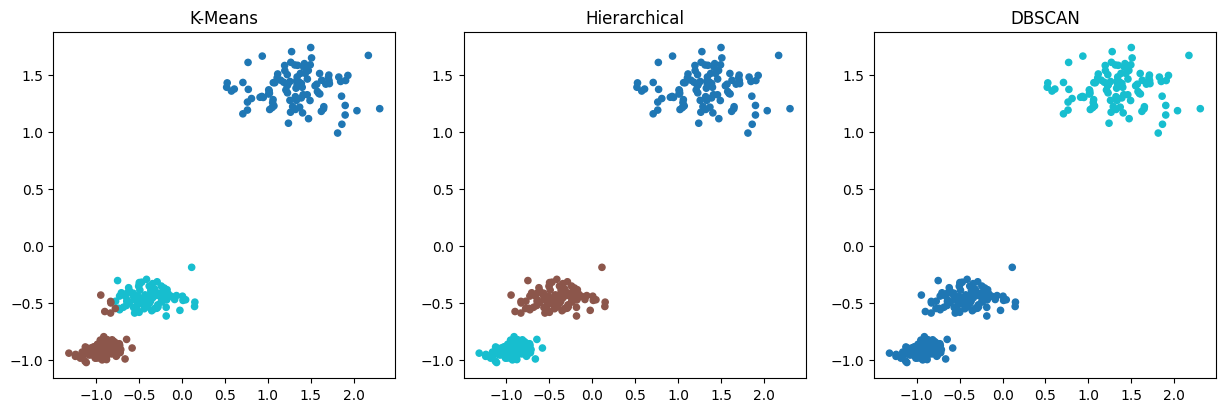

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))
for ax, labels, judul in zip(axes, [labels_kmeans, labels_agglo, labels_dbscan],
                             ["K-Means", "Hierarchical", "DBSCAN"]):
    ax.scatter(X_scaled[:, 0], X_scaled[:, 1], c=labels, cmap="tab10", s=20)
    ax.set_title(judul)
plt.show()

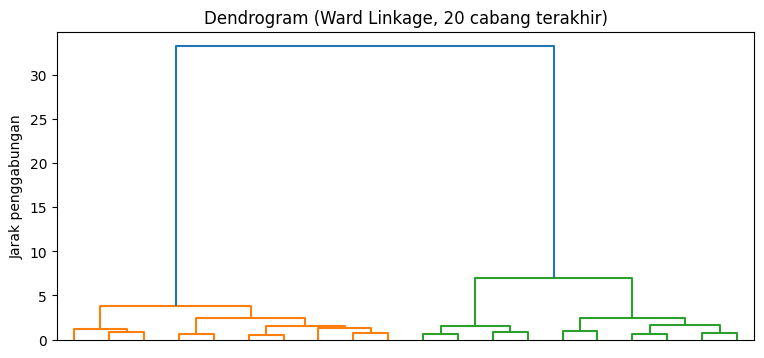

In [7]:
# Dendrogram (Ward) sebagai pelengkap
Z = linkage(X_scaled, method="ward")
plt.figure(figsize=(9, 4))
dendrogram(Z, truncate_mode="lastp", p=20, no_labels=True)
plt.title("Dendrogram (Ward Linkage, 20 cabang terakhir)"); plt.ylabel("Jarak penggabungan"); plt.show()

## Bagian B — Latihan Praktikum

(240, 4)


,Age,Annual Income (k$),Spending Score (1-100),segmen_asli
0,60,82.6,66.0,Target Utama
1,30,77.4,31.0,Pelit/Hati-hati
2,56,56.3,35.0,Standar
3,47,50.7,58.0,Standar
4,65,96.0,80.0,Target Utama


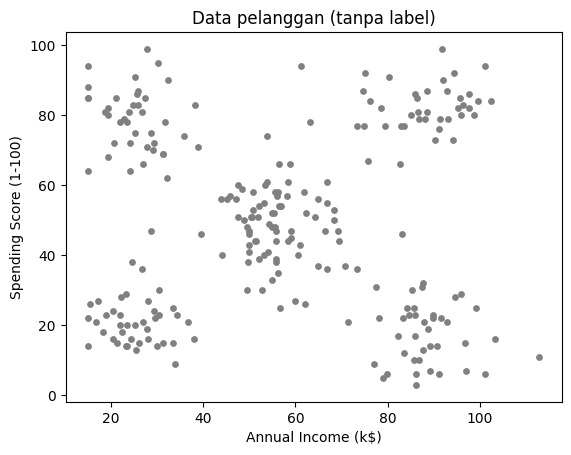

In [8]:
rng = np.random.default_rng(2024)
def grup(n, inc, spd, nama):
    return pd.DataFrame({
        "Age": rng.integers(18, 70, n),
        "Annual Income (k$)": rng.normal(inc[0], inc[1], n).clip(15, 140),
        "Spending Score (1-100)": rng.normal(spd[0], spd[1], n).clip(1, 99),
        "segmen_asli": nama})
df = pd.concat([grup(40, (25, 7), (20, 8), "Hemat"),
                grup(40, (25, 7), (80, 8), "Impulsif"),
                grup(80, (55, 9), (50, 9), "Standar"),
                grup(40, (88, 8), (17, 8), "Pelit/Hati-hati"),
                grup(40, (88, 8), (82, 8), "Target Utama")], ignore_index=True)
df = df.sample(frac=1, random_state=1).reset_index(drop=True)
df["Annual Income (k$)"] = df["Annual Income (k$)"].round(1); df["Spending Score (1-100)"] = df["Spending Score (1-100)"].round(0)
print(df.shape); display(df.head())

fitur = ["Annual Income (k$)", "Spending Score (1-100)"]
Xm = StandardScaler().fit_transform(df[fitur])
plt.scatter(df[fitur[0]], df[fitur[1]], s=15, color="gray"); plt.xlabel(fitur[0]); plt.ylabel(fitur[1])
plt.title("Data pelanggan (tanpa label)"); plt.show()

### Praktikum 1 — Menentukan k Optimal (Elbow Method dan Silhouette Score, k = 2…10)

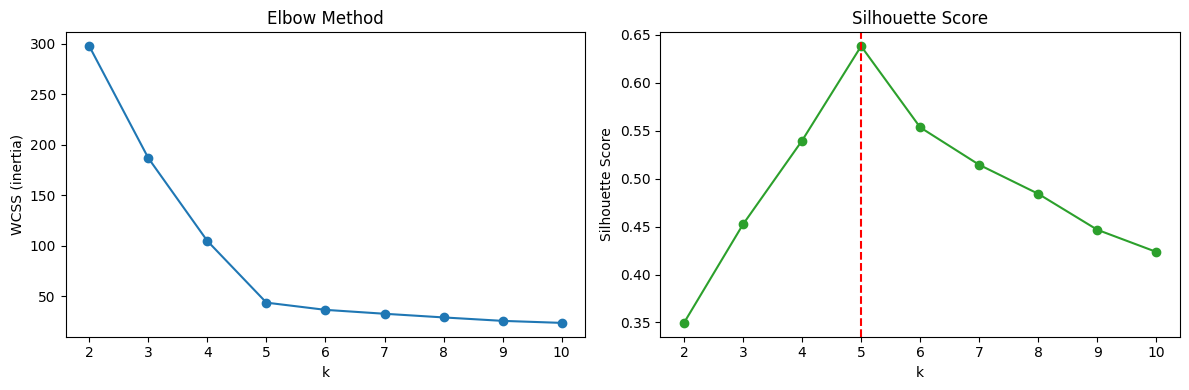

,k,WCSS,Penurunan WCSS (%),Silhouette
0,2,297.381,NaN,0.350
1,3,186.755,37.200,0.452
2,4,104.827,43.869,0.540
3,5,43.888,58.133,0.638
4,6,36.756,16.250,0.553
5,7,32.898,10.497,0.514
6,8,29.270,11.026,0.484
7,9,25.872,11.609,0.447
8,10,23.877,7.712,0.424


k dengan Silhouette tertinggi: 5


In [9]:
ks = list(range(2, 11))
inertia, sil = [], []
for k in ks:
    km = KMeans(n_clusters=k, n_init=10, random_state=42).fit(Xm)
    inertia.append(km.inertia_)
    sil.append(silhouette_score(Xm, km.labels_))

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(ks, inertia, 'o-'); axes[0].set_xlabel("k"); axes[0].set_ylabel("WCSS (inertia)"); axes[0].set_title("Elbow Method")
axes[1].plot(ks, sil, 'o-', color="tab:green"); axes[1].set_xlabel("k"); axes[1].set_ylabel("Silhouette Score"); axes[1].set_title("Silhouette Score")
k_sil = ks[int(np.argmax(sil))]
axes[1].axvline(k_sil, ls="--", color="red"); plt.tight_layout(); plt.show()

tabel_k = pd.DataFrame({"k": ks, "WCSS": inertia, "Penurunan WCSS (%)": [np.nan] + [100 * (inertia[i-1] - inertia[i]) / inertia[i-1] for i in range(1, len(ks))],
                        "Silhouette": sil}).round(3)
display(tabel_k)
print("k dengan Silhouette tertinggi:", k_sil)

### Praktikum 2 — Segmentasi dengan Tiga Algoritma (Praktikum 10.7)

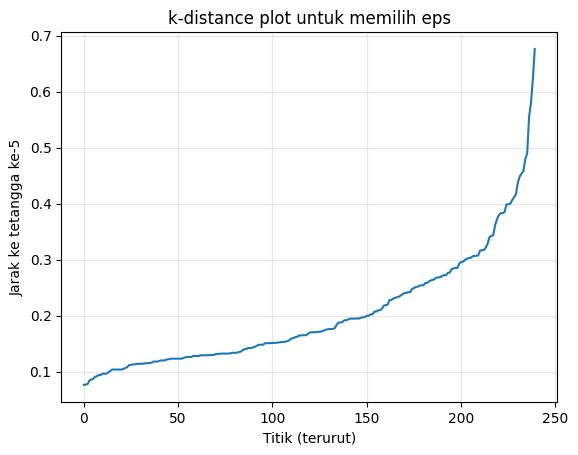

In [10]:
K = k_sil   # jumlah cluster dari Praktikum 1

labels_km = KMeans(n_clusters=K, n_init=10, random_state=42).fit_predict(Xm)
labels_ag = AgglomerativeClustering(n_clusters=K, linkage="ward").fit_predict(Xm)

# DBSCAN: bantu pilih eps dengan grafik k-distance (jarak ke tetangga ke-min_samples)
from sklearn.neighbors import NearestNeighbors
min_samples = 5
jarak = np.sort(NearestNeighbors(n_neighbors=min_samples).fit(Xm).kneighbors(Xm)[0][:, -1])
plt.plot(jarak); plt.xlabel("Titik (terurut)"); plt.ylabel(f"Jarak ke tetangga ke-{min_samples}")
plt.title("k-distance plot untuk memilih eps"); plt.grid(alpha=.3); plt.show()

In [ ]:
# Telusuri beberapa nilai eps
for eps in [0.15, 0.2, 0.25, 0.3, 0.35, 0.4, 0.5]:
    lb = DBSCAN(eps=eps, min_samples=min_samples).fit_predict(Xm)
    print(f"eps={eps}: cluster={len(set(lb) - {-1})}, noise={(lb == -1).sum()}")

eps=0.15: cluster=7, noise=104
eps=0.2: cluster=6, noise=54
eps=0.25: cluster=5, noise=35
eps=0.3: cluster=5, noise=13
eps=0.35: cluster=4, noise=7
eps=0.4: cluster=3, noise=3
eps=0.5: cluster=2, noise=2


,Jumlah cluster,Noise,Silhouette (tanpa noise),ARI vs segmen asli
Algoritma,,,,
K-Means,5,0,0.638,0.976
Hierarchical (Ward),5,0,0.619,0.941
"DBSCAN (eps=0.3, min_samples=5)",5,13,0.668,0.926


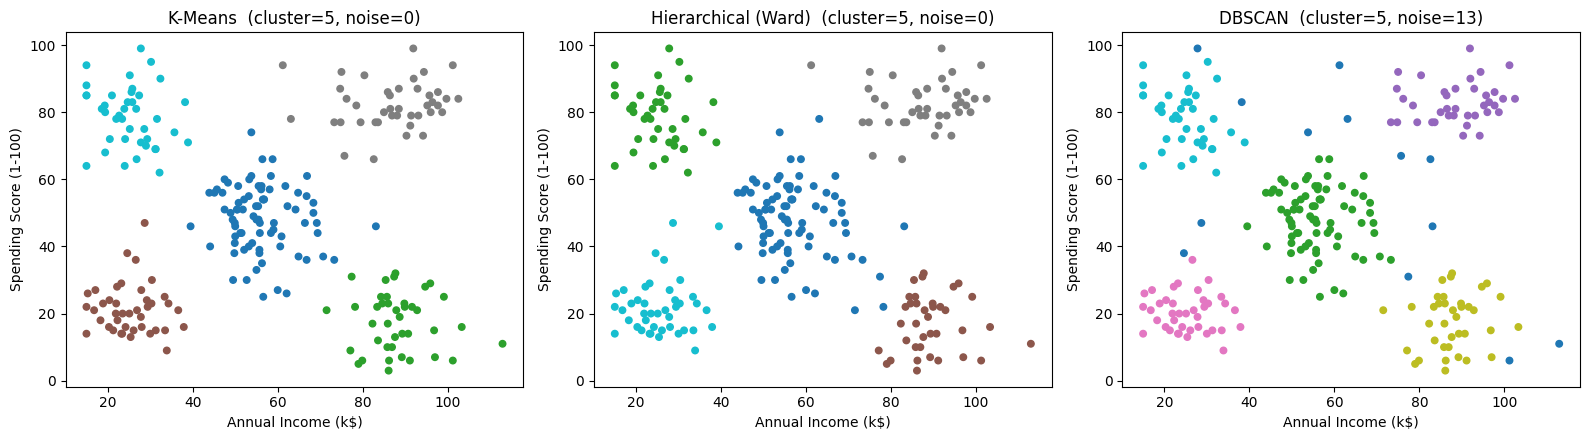

In [11]:
EPS = 0.3
labels_db = DBSCAN(eps=EPS, min_samples=min_samples).fit_predict(Xm)

def ringkas(nama, lb):
    ada = lb != -1
    n_cl = len(set(lb) - {-1})
    s = silhouette_score(Xm[ada], lb[ada]) if n_cl > 1 else np.nan
    return {"Algoritma": nama, "Jumlah cluster": n_cl, "Noise": int((~ada).sum()),
            "Silhouette (tanpa noise)": s,
            "ARI vs segmen asli": adjusted_rand_score(df["segmen_asli"], lb)}

tabel_algo = pd.DataFrame([ringkas("K-Means", labels_km), ringkas("Hierarchical (Ward)", labels_ag),
                           ringkas(f"DBSCAN (eps={EPS}, min_samples={min_samples})", labels_db)]).set_index("Algoritma").round(3)
display(tabel_algo)

fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
for ax, lb, judul in zip(axes, [labels_km, labels_ag, labels_db], ["K-Means", "Hierarchical (Ward)", "DBSCAN"]):
    ax.scatter(df[fitur[0]], df[fitur[1]], c=lb, cmap="tab10", s=22)
    ax.set_title(f"{judul}  (cluster={len(set(lb) - {-1})}, noise={(lb == -1).sum()})")
    ax.set_xlabel(fitur[0]); ax.set_ylabel(fitur[1])
plt.tight_layout(); plt.show()

In [12]:
# Profil segmen dari K-Means untuk interpretasi bisnis
df["cluster_kmeans"] = labels_km
profil = df.groupby("cluster_kmeans").agg(jumlah=("Age", "size"), usia_rata2=("Age", "mean"),
                                          pendapatan_k=(fitur[0], "mean"), skor_belanja=(fitur[1], "mean")).round(1)
profil

,jumlah,usia_rata2,pendapatan_k,skor_belanja
cluster_kmeans,,,,
0,78,45.2,56.2,48.2
1,40,41.2,88.3,17.5
2,41,42.6,25.4,21.4
3,41,42.7,87.1,82.2
4,40,42.0,25.3,78.8
